# Understanding Statistical Inference and Uncertainty through A/B Testing
**DS-A2 | Inference and Uncertainty Notebook**

This is a simulation for a Data Science assignment, not a real teaching experiment.
The results cannot establish that a teaching method actually works. Scores are
unbounded normal draws; some can fall outside the usual 0-100 exam scale.

Run all cells in order from the project directory. The notebook recreates its CSVs,
figures, report and README. No data download is needed.

## Part 1 — Research Question and Data Simulation
### Plan specified before generating any observations
Does the population mean exam score differ between traditional teaching (A) and a
new method (B)? The estimand is $\Delta = \mu_B-\mu_A$, in score points.

- $H_0: \Delta=0$; $H_1: \Delta\ne0$ (two-sided).
- Significance level: $\alpha=0.05$; confidence level: 95%.
- Minimum meaningful positive improvement: **5 points**. A negative difference of
  magnitude 5 would also be a meaningful change, but would favor A.
- Fixed simulation settings: $\mu_A=70$, $\mu_B=75$, $\sigma_A=\sigma_B=15$,
  and **100 observations per group** (200 total).
- Main sample seed: 42. Separate fixed seeds 43, 44 and 45 are used for subsequent
  experiments, so changes to one experiment do not alter another's random stream.

### Assumptions
Students are independent within and between groups; each sample represents its
stated population; observations have finite variance. Normal populations are used
here to make the model simple. Welch allows unequal variances, but does not remove
dependence, selection bias or severe distribution problems. A causal interpretation
in a real study would also need a suitable randomized design.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from IPython.display import display, Markdown

RESULTS = Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 42
ALPHA = 0.05
MEAN_A, MEAN_B, SIGMA, N = 70, 75, 15, 100
TRUE_DELTA = MEAN_B - MEAN_A
MIN_EFFECT = 5
BLUE, ORANGE = '#2864A0', '#C77925'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110,
                     'savefig.dpi': 170})
print(f'Python {sys.version.split()[0]}; NumPy {np.__version__}; '
      f'SciPy {scipy.__version__}; Pandas {pd.__version__}')

def save_plot(fig, name):
    fig.savefig(FIGURES / name, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

Python 3.12.14; NumPy 2.5.4; SciPy 1.18.1; Pandas 3.0.6


,count,mean,std
group,,,
A,100,69.246,11.650
B,100,74.841,14.693


Observed mean difference (B - A): 5.595 points


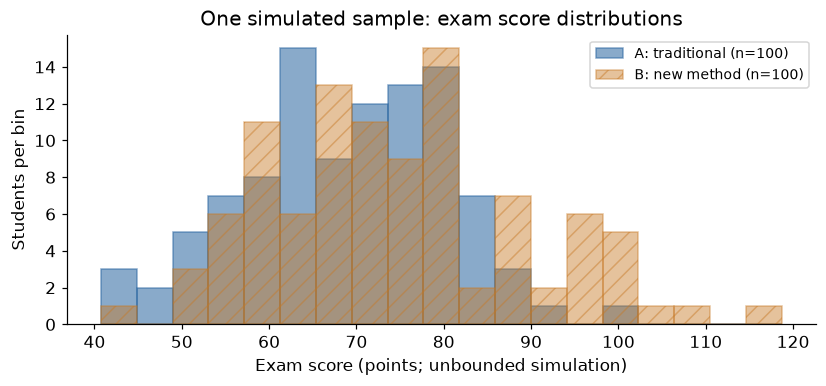

In [2]:
rng = np.random.default_rng(SEED)
group_a = rng.normal(MEAN_A, SIGMA, N)
group_b = rng.normal(MEAN_B, SIGMA, N)
sample_data = pd.DataFrame({'group': np.repeat(['A', 'B'], N),
                            'student_id': np.tile(np.arange(1, N + 1), 2),
                            'score': np.concatenate([group_a, group_b])})
sample_data.to_csv(RESULTS / 'sample_data.csv', index=False)
sample_summary = sample_data.groupby('group')['score'].agg(['count', 'mean', 'std'])
difference = group_b.mean() - group_a.mean()
display(sample_summary.round(3))
print(f'Observed mean difference (B - A): {difference:.3f} points')

fig, ax = plt.subplots(figsize=(7.4, 3.4), layout='constrained')
bins = np.linspace(min(group_a.min(), group_b.min()),
                   max(group_a.max(), group_b.max()), 20)
ax.hist(group_a, bins=bins, alpha=0.55, color=BLUE, edgecolor=BLUE,
        label='A: traditional (n=100)')
ax.hist(group_b, bins=bins, alpha=0.45, color=ORANGE, edgecolor=ORANGE,
        hatch='//', label='B: new method (n=100)')
ax.set(title='One simulated sample: exam score distributions',
       xlabel='Exam score (points; unbounded simulation)', ylabel='Students per bin')
ax.legend(fontsize=9)
save_plot(fig, 'sample_distributions.png')

In [3]:
display(Markdown(f'The observed means are **{group_a.mean():.2f}** (A) and '
                 f'**{group_b.mean():.2f}** (B), with sample SDs '
                 f'{group_a.std(ddof=1):.2f} and {group_b.std(ddof=1):.2f}. '
                 'The population means 70 and 75 and SD 15 were chosen before '
                 'sampling; these sample statistics fluctuate because they use '
                 'only a finite set of random observations. Sample SD uses ddof=1.'))

The observed means are **69.25** (A) and **74.84** (B), with sample SDs 11.65 and 14.69. The population means 70 and 75 and SD 15 were chosen before sampling; these sample statistics fluctuate because they use only a finite set of random observations. Sample SD uses ddof=1.

## Part 2 — Sampling Distribution
Draw **1,000 independent pairs of samples**, keeping the same populations and 100
observations per group. Each row of the saved CSV is one actual repeated experiment.
The theoretical standard error under independence is

$$SE(\widehat\Delta)=\sqrt{\sigma_A^2/n_A+\sigma_B^2/n_B}.$$

Different draws give different estimates. The estimator is centered on the true
difference. Doubling both sample sizes multiplies SE by $1/\sqrt{2}$; this is a
theoretical comparison, not a second sampling experiment.

Sampling mean: 4.9788; empirical SD: 2.0818
Theoretical SE: 2.1213; SE at n=200 per group: 1.5000


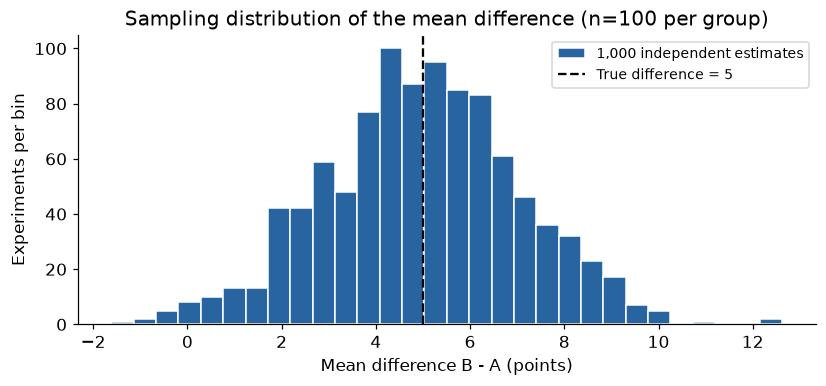

In [4]:
sampling_rng = np.random.default_rng(43)
sampling_rows = []
for replicate in range(1, 1001):
    a = sampling_rng.normal(MEAN_A, SIGMA, N)
    b = sampling_rng.normal(MEAN_B, SIGMA, N)
    sampling_rows.append({'replicate': replicate, 'seed': 43, 'n_a': N, 'n_b': N,
                          'mean_a': a.mean(), 'mean_b': b.mean(),
                          'sd_a': a.std(ddof=1), 'sd_b': b.std(ddof=1),
                          'difference': b.mean() - a.mean()})
simulation_results = pd.DataFrame(sampling_rows)
simulation_results.to_csv(RESULTS / 'simulation_results.csv', index=False)
sampling_mean = simulation_results['difference'].mean()
sampling_sd = simulation_results['difference'].std(ddof=1)
theoretical_se = np.sqrt(SIGMA**2 / N + SIGMA**2 / N)
print(f'Sampling mean: {sampling_mean:.4f}; empirical SD: {sampling_sd:.4f}')
print(f'Theoretical SE: {theoretical_se:.4f}; SE at n=200 per group: '
      f'{np.sqrt(2 * SIGMA**2 / 200):.4f}')

fig, ax = plt.subplots(figsize=(7.4, 3.4), layout='constrained')
ax.hist(simulation_results['difference'], bins=30, color=BLUE,
        edgecolor='white', label='1,000 independent estimates')
ax.axvline(TRUE_DELTA, color='black', linestyle='--', label='True difference = 5')
ax.set(title='Sampling distribution of the mean difference (n=100 per group)',
       xlabel='Mean difference B - A (points)', ylabel='Experiments per bin')
ax.legend(fontsize=9)
save_plot(fig, 'sampling_distribution.png')

In [5]:
display(Markdown(f'The simulated center is **{sampling_mean:.3f} points**, close '
                 f'to the true 5-point difference. The simulated SD '
                 f'(**{sampling_sd:.3f}**) is close to the theoretical SE '
                 f'(**{theoretical_se:.3f}**). Neither equality is expected exactly '
                 'with 1,000 repetitions. Increasing sample size reduces the '
                 'variation of an estimate, even when individual scores remain noisy.'))

The simulated center is **4.979 points**, close to the true 5-point difference. The simulated SD (**2.082**) is close to the theoretical SE (**2.121**). Neither equality is expected exactly with 1,000 repetitions. Increasing sample size reduces the variation of an estimate, even when individual scores remain noisy.

## Part 3 — Confidence Interval and Hypothesis Testing
Welch's t-test compares independent means without requiring equal population
variances. Use B as the first argument to keep the sign **B - A**. Define
$v_A=s_A^2/n_A$ and $v_B=s_B^2/n_B$. Then

$$\widehat{SE}=\sqrt{v_A+v_B},\qquad t=\widehat\Delta/\widehat{SE},$$
$$\nu=\frac{(v_A+v_B)^2}{v_A^2/(n_A-1)+v_B^2/(n_B-1)},$$
$$CI_{95\%}=\widehat\Delta\ \pm\ t_{0.975,\nu}\widehat{SE}.$$

The p-value is the probability, under the null model and its assumptions, of a
test statistic at least as extreme in either direction. It is **not** the
probability that the null hypothesis is true. A 95% confidence procedure covers
the fixed population difference in approximately 95% of repeated samples under
its assumptions; it does not assign 95% probability to this fixed parameter.
The Welch t approximation is especially appropriate here with normal populations.

Method reference: [SciPy ttest_ind documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).

,difference_B_minus_A,SE,df,t,p_value,CI_low,CI_high,reject_H0
0,5.594567,1.875105,188.219459,2.983602,0.003226,1.895645,9.293488,True


PASS: manual t, p-value, degrees of freedom and CI agree with SciPy.


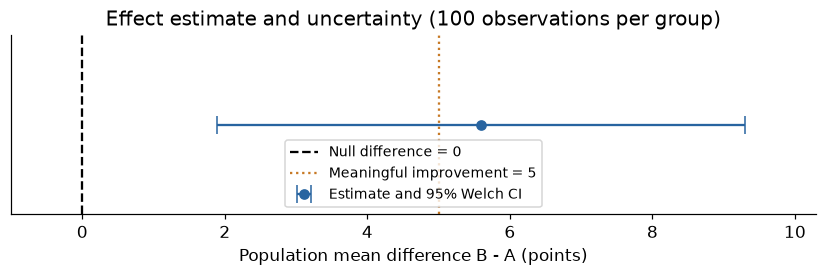

In [6]:
welch = stats.ttest_ind(group_b, group_a, equal_var=False, alternative='two-sided')
scipy_ci = welch.confidence_interval(confidence_level=0.95)
v_a = group_a.var(ddof=1) / N
v_b = group_b.var(ddof=1) / N
estimated_se = np.sqrt(v_a + v_b)
welch_df = (v_a + v_b)**2 / (v_a**2 / (N - 1) + v_b**2 / (N - 1))
t_statistic = difference / estimated_se
p_manual = 2 * stats.t.sf(abs(t_statistic), welch_df)
margin = stats.t.ppf(0.975, welch_df) * estimated_se
ci_low, ci_high = difference - margin, difference + margin
np.testing.assert_allclose([t_statistic, p_manual, welch_df, ci_low, ci_high],
                           [welch.statistic, welch.pvalue, welch.df,
                            scipy_ci.low, scipy_ci.high], rtol=1e-12)
display(pd.DataFrame([{'difference_B_minus_A': difference, 'SE': estimated_se,
                       'df': welch_df, 't': t_statistic, 'p_value': welch.pvalue,
                       'CI_low': ci_low, 'CI_high': ci_high,
                       'reject_H0': welch.pvalue < ALPHA}]).round(6))
print('PASS: manual t, p-value, degrees of freedom and CI agree with SciPy.')

fig, ax = plt.subplots(figsize=(7.4, 2.4), layout='constrained')
ax.errorbar(difference, 0, xerr=[[difference-ci_low], [ci_high-difference]],
            fmt='o', color=BLUE, capsize=6, label='Estimate and 95% Welch CI')
ax.axvline(0, color='black', linestyle='--', label='Null difference = 0')
ax.axvline(MIN_EFFECT, color=ORANGE, linestyle=':', label='Meaningful improvement = 5')
ax.set(xlabel='Population mean difference B - A (points)', yticks=[],
       title='Effect estimate and uncertainty (100 observations per group)', ylim=(-1, 1))
ax.set_xlim(min(-1, ci_low-1), max(7, ci_high+1))
ax.legend(loc='lower center', fontsize=9)
save_plot(fig, 'effect_confidence_interval.png')

In [7]:
decision = 'reject' if welch.pvalue < ALPHA else 'do not reject'
display(Markdown(f'We **{decision} $H_0$**: the estimated difference is '
                 f'**{difference:.3f} points**, 95% CI '
                 f'**[{ci_low:.3f}, {ci_high:.3f}]**, p = **{welch.pvalue:.6f}**. '
                 f'The interval includes the 5-point meaningful-improvement threshold '
                 f'and extends below it. Thus statistical significance does not '
                 f'establish an improvement of at least 5 points. This inference '
                 f'describes the simulated populations only.'))

We **reject $H_0$**: the estimated difference is **5.595 points**, 95% CI **[1.896, 9.293]**, p = **0.003226**. The interval includes the 5-point meaningful-improvement threshold and extends below it. Thus statistical significance does not establish an improvement of at least 5 points. This inference describes the simulated populations only.

## Part 4 — Statistical Power Simulation
For each prespecified condition, draw **500 independent experiments** and compute
the fraction with two-sided Welch p &lt; 0.05. Other factors stay at the baseline
(100 per group, SD 15, difference 5). The zero-effect condition measures the
**Type I error rate**, not power to detect a real effect. All reported n values
are **per group**, not the combined total.

Monte Carlo estimates also have uncertainty: the approximate Monte Carlo standard
error of a rejection fraction $\hat p$ is $\sqrt{\hat p(1-\hat p)/R}$.
Error bars below show 95% Wilson binomial intervals for the simulated rejection
probability. These remain informative even if all 500 tests reject. They describe
simulation precision, not a confidence interval for the teaching effect.

In [8]:
def simulate_power(n, sigma, delta, rng, repeats=500):
    rows = []
    for replicate in range(1, repeats + 1):
        a = rng.normal(MEAN_A, sigma, n)
        b = rng.normal(MEAN_A + delta, sigma, n)
        test = stats.ttest_ind(b, a, equal_var=False)
        rows.append({'replicate': replicate, 'n_per_group': n, 'sigma': sigma,
                     'delta': delta, 'mean_a': a.mean(), 'mean_b': b.mean(),
                     'difference': b.mean() - a.mean(), 'sd_a': a.std(ddof=1),
                     'sd_b': b.std(ddof=1), 't': test.statistic, 'df': test.df,
                     'p_value': test.pvalue, 'reject': test.pvalue < ALPHA})
    return pd.DataFrame(rows)

power_rng = np.random.default_rng(44)
conditions = [('sample_size', n, SIGMA, TRUE_DELTA) for n in [20, 50, 100, 200]]
conditions += [('noise', N, sigma, TRUE_DELTA) for sigma in [5, 10, 15, 20]]
conditions += [('effect', N, SIGMA, delta) for delta in [0, 2, 5, 8]]
power_frames = []
for experiment, n, sigma, delta in conditions:
    frame = simulate_power(n, sigma, delta, power_rng)
    frame['experiment'] = experiment
    frame['seed'] = 44
    power_frames.append(frame)
power_results = pd.concat(power_frames, ignore_index=True)
power_results.to_csv(RESULTS / 'power_results.csv', index=False)
power_summary = (power_results.groupby(['experiment', 'n_per_group', 'sigma', 'delta'],
                                      sort=False)['reject']
                 .agg(rejection_rate='mean', repeats='size', rejected='sum').reset_index())
power_summary['mc_se'] = np.sqrt(power_summary.rejection_rate *
                               (1 - power_summary.rejection_rate) / power_summary.repeats)
power_intervals = [stats.binomtest(int(row.rejected), int(row.repeats)).proportion_ci(method='wilson')
                   for row in power_summary.itertuples()]
power_summary['mc_ci_low'] = [ci.low for ci in power_intervals]
power_summary['mc_ci_high'] = [ci.high for ci in power_intervals]
display(power_summary.round(4))

,experiment,n_per_group,sigma,delta,rejection_rate,repeats,rejected,mc_se,mc_ci_low,mc_ci_high
0,sample_size,20,15,5,0.162,500,81,0.0165,0.1323,0.1969
1,sample_size,50,15,5,0.368,500,184,0.0216,0.3269,0.4111
2,sample_size,100,15,5,0.620,500,310,0.0217,0.5767,0.6615
3,sample_size,200,15,5,0.928,500,464,0.0116,0.9019,0.9475
4,noise,100,5,5,1.000,500,500,0.0000,0.9924,1.0000
5,noise,100,10,5,0.928,500,464,0.0116,0.9019,0.9475
6,noise,100,15,5,0.680,500,340,0.0209,0.6379,0.7194
7,noise,100,20,5,0.450,500,225,0.0222,0.4069,0.4938
8,effect,100,15,0,0.042,500,21,0.0090,0.0276,0.0634
9,effect,100,15,2,0.144,500,72,0.0157,0.1159,0.1775


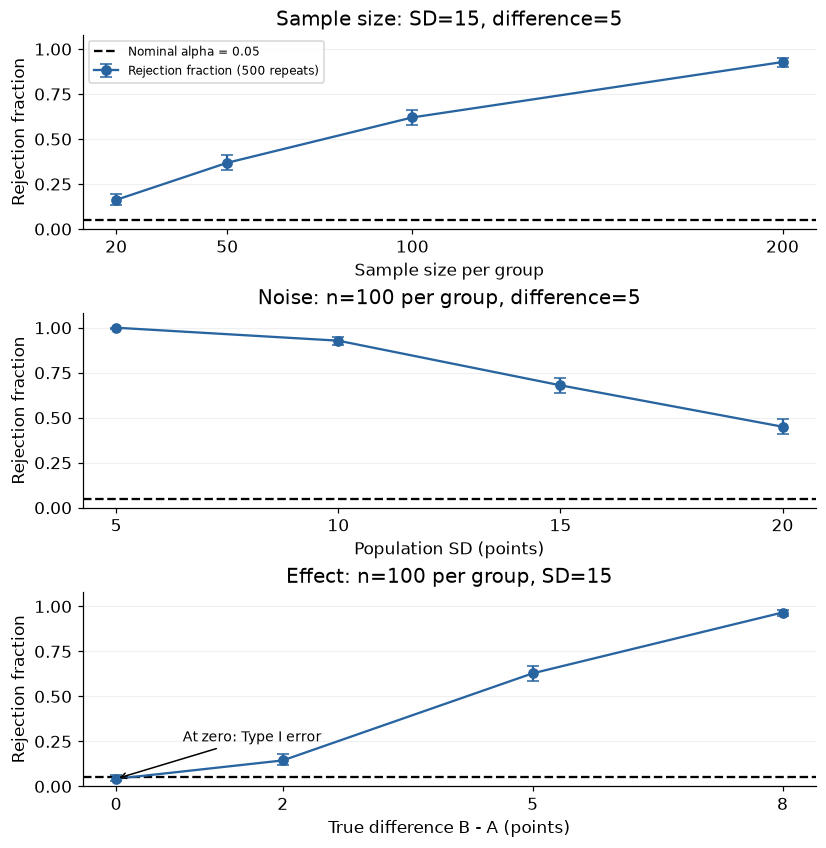

Power rises from **16.2%** at n=20 to **92.8%** at n=200 per group. Increasing SD from 5 to 20 changes power from **100.0%** to **45.0%**. The zero-effect rejection rate is **4.2%**; at a true difference of 8 it is **96.6%**. More observations, less noise and larger effects make a difference easier to detect in these simulations. Identical baseline settings appear in all three experiments but use independent repetitions, so their estimated power need not be identical.

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(7.4, 7.6), layout='constrained')
for ax, experiment, column, label, subtitle in zip(
    axes, ['sample_size', 'noise', 'effect'], ['n_per_group', 'sigma', 'delta'],
    ['Sample size per group', 'Population SD (points)', 'True difference B - A (points)'],
    ['Sample size: SD=15, difference=5',
     'Noise: n=100 per group, difference=5',
     'Effect: n=100 per group, SD=15']):
    subset = power_summary[power_summary.experiment == experiment].sort_values(column)
    rates = subset.rejection_rate.to_numpy()
    ax.errorbar(subset[column], rates,
                yerr=[rates-subset.mc_ci_low.to_numpy(), subset.mc_ci_high.to_numpy()-rates],
                color=BLUE, marker='o', capsize=4, label='Rejection fraction (500 repeats)')
    ax.axhline(ALPHA, color='black', linestyle='--', label='Nominal alpha = 0.05')
    ax.set(title=subtitle, xlabel=label, ylabel='Rejection fraction', ylim=(0, 1.08))
    ax.set_xticks(subset[column])
    ax.grid(axis='y', alpha=0.18)
    if experiment == 'effect':
        ax.annotate('At zero: Type I error', (0, rates[0]), xytext=(0.8, 0.25),
                    arrowprops={'arrowstyle': '->', 'color': 'black'}, fontsize=9)
    if experiment == 'sample_size':
        ax.legend(fontsize=8, loc='upper left')
save_plot(fig, 'power_curves.png')

n_power = power_summary[power_summary.experiment == 'sample_size'].sort_values('n_per_group')
noise_power = power_summary[power_summary.experiment == 'noise'].sort_values('sigma')
effect_power = power_summary[power_summary.experiment == 'effect'].sort_values('delta')
null_rate = float(effect_power.loc[effect_power.delta == 0, 'rejection_rate'].iloc[0])
display(Markdown(f'Power rises from **{n_power.rejection_rate.iloc[0]:.1%}** at n=20 '
                 f'to **{n_power.rejection_rate.iloc[-1]:.1%}** at n=200 per group. '
                 f'Increasing SD from 5 to 20 changes power from '
                 f'**{noise_power.rejection_rate.iloc[0]:.1%}** to '
                 f'**{noise_power.rejection_rate.iloc[-1]:.1%}**. '
                 f'The zero-effect rejection rate is **{null_rate:.1%}**; '
                 f'at a true difference of 8 it is **{effect_power.rejection_rate.iloc[-1]:.1%}**. '
                 'More observations, less noise and larger effects make a difference '
                 'easier to detect in these simulations. Identical baseline settings '
                 'appear in all three experiments but use independent repetitions, '
                 'so their estimated power need not be identical.'))

## Part 5 — Assumption-Violating Counterexample
Both population means are 70, so the true difference is zero. Group A has **n=25,
SD=20**, and Group B has **n=100, SD=5**. Samples remain independent and normal.
Only the equal-variance assumption of the pooled Student t-test is violated; this
is not a violation of Welch's variance assumptions.

For Student's test, use the pooled variance
$s_p^2=((n_A-1)s_A^2+(n_B-1)s_B^2)/(n_A+n_B-2)$,
standard error $s_p\sqrt{1/n_A+1/n_B}$ and $n_A+n_B-2$ degrees of freedom.
Welch uses the earlier formulas. Both tests use the **same pair of samples** in
each of 1,000 independent repetitions, allowing a fair comparison.
Save both p-values and matching 95% interval endpoints for every repetition.
Coverage is the fraction of intervals containing the true difference zero.

,method,repeats,type1_rate,coverage,type1_mc_se,coverage_mc_se
0,Student,1000,0.301,0.699,0.0145,0.0145
1,Welch,1000,0.056,0.944,0.0073,0.0073


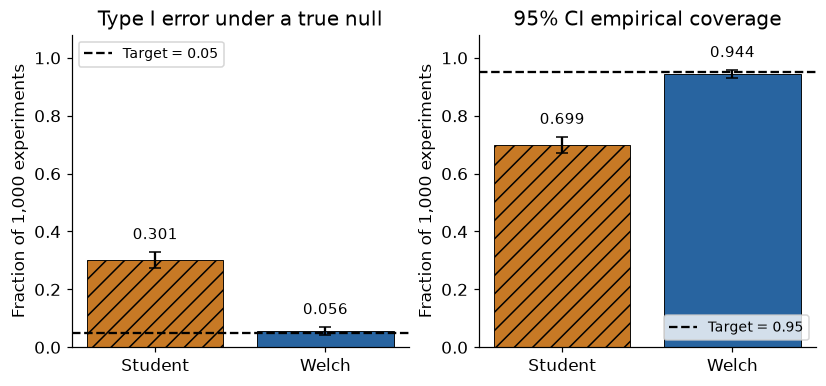

In [10]:
counter_rng = np.random.default_rng(45)
counter_rows = []
for replicate in range(1, 1001):
    a = counter_rng.normal(70, 20, 25)
    b = counter_rng.normal(70, 5, 100)
    estimate = b.mean() - a.mean()
    for method, equal_var in [('Student', True), ('Welch', False)]:
        test = stats.ttest_ind(b, a, equal_var=equal_var)
        ci = test.confidence_interval(confidence_level=0.95)
        # Check manual standard errors and degrees of freedom on every repetition.
        var_a, var_b = a.var(ddof=1), b.var(ddof=1)
        if equal_var:
            pooled_var = (24 * var_a + 99 * var_b) / 123
            se = np.sqrt(pooled_var * (1/25 + 1/100))
            df = 123
        else:
            va, vb = var_a/25, var_b/100
            se = np.sqrt(va + vb)
            df = (va + vb)**2 / (va**2/24 + vb**2/99)
        half_width = stats.t.ppf(0.975, df) * se
        np.testing.assert_allclose([test.df, ci.low, ci.high],
                                   [df, estimate-half_width, estimate+half_width], rtol=1e-11)
        counter_rows.append({'replicate': replicate, 'seed': 45, 'method': method,
                            'n_a': 25, 'n_b': 100, 'sigma_a': 20, 'sigma_b': 5,
                            'true_delta': 0, 'mean_a': a.mean(), 'mean_b': b.mean(),
                            'sd_a': np.sqrt(var_a), 'sd_b': np.sqrt(var_b),
                            'difference': estimate, 'SE': se, 't': test.statistic,
                            'df': test.df, 'p_value': test.pvalue,
                            'reject': test.pvalue < ALPHA,
                            'CI_low': ci.low, 'CI_high': ci.high,
                            'covers_zero': ci.low <= 0 <= ci.high})
counterexample_results = pd.DataFrame(counter_rows)
counterexample_results.to_csv(RESULTS / 'counterexample_results.csv', index=False)
counter_summary = (counterexample_results.groupby('method', sort=False)
                   .agg(repeats=('reject', 'size'), type1_rate=('reject', 'mean'),
                        coverage=('covers_zero', 'mean')).reset_index())
counter_summary['type1_mc_se'] = np.sqrt(counter_summary.type1_rate *
                                        (1-counter_summary.type1_rate)/1000)
counter_summary['coverage_mc_se'] = np.sqrt(counter_summary.coverage *
                                           (1-counter_summary.coverage)/1000)
display(counter_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.4), layout='constrained')
for ax, column, mc_column, target, title in zip(
    axes, ['type1_rate', 'coverage'], ['type1_mc_se', 'coverage_mc_se'],
    [ALPHA, 0.95], ['Type I error under a true null', '95% CI empirical coverage']):
    bars = ax.bar(counter_summary.method, counter_summary[column],
                  color=[ORANGE, BLUE], edgecolor='black', linewidth=0.6,
                  yerr=1.96*counter_summary[mc_column], capsize=4)
    bars[0].set_hatch('//')
    ax.axhline(target, color='black', linestyle='--', label=f'Target = {target:.2f}')
    ax.set(title=title, ylabel='Fraction of 1,000 experiments', ylim=(0, 1.08))
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in counter_summary[column]],
                 padding=6, fontsize=10)
    ax.legend(fontsize=9, loc='upper left' if column == 'type1_rate' else 'lower right')
save_plot(fig, 'counterexample_comparison.png')

In [11]:
student_result = counter_summary.set_index('method').loc['Student']
welch_result = counter_summary.set_index('method').loc['Welch']
display(Markdown(f'Student rejects a true null in **{student_result.type1_rate:.1%}** '
                 f'of experiments and its intervals cover zero in '
                 f'**{student_result.coverage:.1%}**. Welch gives '
                 f'**{welch_result.type1_rate:.1%}** Type I error and '
                 f'**{welch_result.coverage:.1%}** coverage. '
                 'Pooling gives the large, low-variance group more weight in the '
                 'variance estimate, whereas the small, high-variance group '
                 'dominates uncertainty in the mean difference. This can make the '
                 'pooled standard error too small and inflate false positives. '
                 'Welch accounts for each group variance and sample size separately. '
                 'Coverage and non-rejection are complementary here because the '
                 'two-sided test and interval use the same method and null value.'))
print(f'True SE in counterexample: {np.sqrt(20**2/25 + 5**2/100):.3f}')
print('SE obtained by substituting population variances into the pooled formula: '
      f'{np.sqrt(((24*20**2 + 99*5**2)/123)*(1/25+1/100)):.3f}')

Student rejects a true null in **30.1%** of experiments and its intervals cover zero in **69.9%**. Welch gives **5.6%** Type I error and **94.4%** coverage. Pooling gives the large, low-variance group more weight in the variance estimate, whereas the small, high-variance group dominates uncertainty in the mean difference. This can make the pooled standard error too small and inflate false positives. Welch accounts for each group variance and sample size separately. Coverage and non-rejection are complementary here because the two-sided test and interval use the same method and null value.

True SE in counterexample: 4.031
SE obtained by substituting population variances into the pooled formula: 2.216


### Limitations and conclusions
The direction and scale of these comparisons apply to the simulated conditions.
There are only 500 or 1,000 repetitions, so error rates and coverage fluctuate.
With 1,000 repeats and a true rejection rate 0.05, the theoretical MC SE is about
0.0069 (0.69 percentage points); exact 5% error is not required. Welch is an
approximation, not a cure for all assumption violations. Dependence, nonrandom
sampling, outliers and bounded real scores were not studied. The initial sample
is one realization; the method cannot certify a real teaching benefit.

## Checks and reproducible deliverables
The following checks run rather than merely describe validation. Formula checks
above independently use sample variances and the t distribution, then compare
with SciPy. Every required CSV is read back and checked against its in-memory table.
No assertion forces simulated power or error rates to match a preferred pattern.

In [12]:
np.testing.assert_allclose(theoretical_se, SIGMA * np.sqrt(2/N), rtol=1e-14)
for filename, expected in [('sample_data.csv', sample_data),
                           ('simulation_results.csv', simulation_results),
                           ('power_results.csv', power_results),
                           ('counterexample_results.csv', counterexample_results)]:
    actual = pd.read_csv(RESULTS / filename)
    pd.testing.assert_frame_equal(actual, expected, check_exact=False, rtol=1e-12, atol=1e-12)
assert len(simulation_results) == 1000
assert len(power_results) == 6000
assert len(counterexample_results) == 2000
assert power_results.groupby(['experiment', 'n_per_group', 'sigma', 'delta']).size().eq(500).all()
np.testing.assert_allclose(counter_summary.type1_rate + counter_summary.coverage, 1)
assert counterexample_results['p_value'].between(0, 1).all()
assert power_results['p_value'].between(0, 1).all()
null_count = int(power_results.query("experiment == 'effect' and delta == 0")['reject'].sum())
null_binomial_ci = stats.binomtest(null_count, 500, p=ALPHA).proportion_ci()
print('PASS: theoretical SE identity; all CSV values; repetition counts; p-value ranges; '
      'counterexample coverage/test duality.')
print(f'Null-condition rejection count: {null_count}/500; exact 95% binomial interval: '
      f'[{null_binomial_ci.low:.4f}, {null_binomial_ci.high:.4f}]')
print('This diagnostic interval is reported honestly; it is not a pass/fail target.')

PASS: theoretical SE identity; all CSV values; repetition counts; p-value ranges; counterexample coverage/test duality.
Null-condition rejection count: 21/500; exact 95% binomial interval: [0.0262, 0.0635]
This diagnostic interval is reported honestly; it is not a pass/fail target.


### Report and project description
The last cells generate a four-page PDF and README from the values computed above.
The README contains a 150-300 word English submission summary. The AI use log is a
separate record of the actual build and validation; it is not overwritten on rerun.

In [13]:
submission_summary = (
    f'This project asks whether traditional and new teaching methods differ in population '
    f'mean exam scores. It uses synthetic normal data, not a real teaching experiment. '
    f'Before sampling, I specified the estimand as mean B minus mean A, a two-sided null '
    f'of zero difference, alpha 0.05, and a meaningful improvement of 5 points. '
    f'With 100 observations per group and seed 42, the observed difference was '
    f'{difference:.3f} points. The Welch test gave p={welch.pvalue:.6f} and a 95% '
    f'confidence interval [{ci_low:.3f}, {ci_high:.3f}]. This supports a nonzero '
    f'simulated difference but does not establish an improvement of at least 5 points. '
    f'Across 1,000 repeated samples, the estimate had mean {sampling_mean:.3f} and '
    f'SD {sampling_sd:.3f}, compared with theoretical SE {theoretical_se:.3f}. '
    f'Power simulations used 500 repetitions per condition. Increasing sample size '
    f'from 20 to 200 per group increased rejection rates from '
    f'{n_power.rejection_rate.iloc[0]:.1%} to {n_power.rejection_rate.iloc[-1]:.1%}; '
    f'greater noise reduced power and larger effects increased it. The zero-effect '
    f'rejection rate was {null_rate:.1%}, representing Type I error. '
    f'In 1,000 equal-mean counterexamples with unequal variances and sample sizes, '
    f'Student and Welch Type I error rates were {student_result.type1_rate:.1%} and '
    f'{welch_result.type1_rate:.1%}; their 95% interval coverage rates were '
    f'{student_result.coverage:.1%} and {welch_result.coverage:.1%}. '
    f'The pooled variance assumption made Student inference unreliable here. '
    f'Finite Monte Carlo precision, independence assumptions and unbounded normal '
    f'scores limit generalization. These results demonstrate statistical methods '
    f'and cannot show that a real teaching method is effective.'
)
word_count = len(submission_summary.split())
assert 150 <= word_count <= 300
print(f'Submission summary: {word_count} words')
display(Markdown(submission_summary))

versions = {'numpy': np.__version__, 'scipy': scipy.__version__, 'pandas': pd.__version__}
readme = f"""# DS-A2 | Inference and Uncertainty Notebook

## Goal and scope
**Understanding Statistical Inference and Uncertainty through A/B Testing**

Compare traditional and new teaching using simulated exam scores. This is a methods
demonstration, not real student data or evidence of teaching effectiveness. All report,
table and chart values come from executed simulations. The five parts in analysis.ipynb
cover a prespecified question, sampling distributions, Welch inference, power, and an
unequal-variance counterexample.

## Install and run
Python 3.12 was used for validation. From this project directory:

```bash
python -m venv .venv
# Windows PowerShell:
./.venv/Scripts/Activate.ps1
# macOS/Linux: source .venv/bin/activate
python -m pip install -r requirements.txt
python -m jupyter nbconvert --execute --to notebook --inplace analysis.ipynb --ExecutePreprocessor.timeout=600
```

The python3 kernel must use the activated environment. If an existing kernel points
elsewhere, register this environment explicitly and select it:

```bash
python -m ipykernel install --user --name ds-a2 --display-name "DS-A2"
python -m jupyter nbconvert --execute --to notebook --inplace analysis.ipynb --ExecutePreprocessor.kernel_name=ds-a2 --ExecutePreprocessor.timeout=600
```

For interactive reading: `python -m jupyterlab analysis.ipynb` (JupyterLab is included
in requirements). Running every cell recreates all numerical results, figures,
report.pdf and README.md in the current project directory. AI_USE_LOG.md is preserved.
No API, GPU, internet data source or external PDF compiler is required after installation.

## Files
```text
DS-A2-Inference-Uncertainty/
  analysis.ipynb
  README.md
  requirements.txt
  report.pdf
  AI_USE_LOG.md
  .gitignore
  results/
    sample_data.csv              # 200 initial individual scores
    simulation_results.csv      # 1,000 independent sampling experiments
    power_results.csv           # 6,000 actual experiments across 12 conditions
    counterexample_results.csv  # 2,000 test/CI records; 1,000 paired experiments
    figures/                    # five PNGs, including three power panels
```

CSV files contain full-precision values. Initial scores are preserved individually;
repeated simulations preserve each replicate's sample summaries and, where relevant,
test statistics, p-values, decisions and confidence intervals. They are not just
hand-written aggregate summaries. Replicate identifiers restart within each condition;
use condition columns with replicate as the key.

## Methods and main results
Estimand: population mean B minus mean A. H0: zero; H1: nonzero; alpha=0.05;
meaningful positive improvement=5 points. Baseline population settings are means
70 and 75, SD=15, and n=100 per group. Seeds: 42 (initial), 43 (sampling), 44 (power),
45 (counterexample). Sample SDs use ddof=1. Welch's SE and Satterthwaite degrees of
freedom are calculated directly and verified against SciPy; see Part 3 for formulas.

- Sample means: A={group_a.mean():.3f}, B={group_b.mean():.3f}.
- Difference={difference:.3f}; 95% Welch CI=[{ci_low:.3f}, {ci_high:.3f}];
  p={welch.pvalue:.6f}; df={welch_df:.3f}.
- Sampling mean={sampling_mean:.3f}, empirical SD={sampling_sd:.3f}, theoretical SE={theoretical_se:.3f}.
- Power at n=20/50/100/200 per group: {', '.join(f'{p:.1%}' for p in n_power.rejection_rate)}.
- Power at SD=5/10/15/20: {', '.join(f'{p:.1%}' for p in noise_power.rejection_rate)}.
- Rejection at effect=0/2/5/8: {', '.join(f'{p:.1%}' for p in effect_power.rejection_rate)}.
  The effect=0 rate is Type I error, not power against a true alternative.
- Counterexample: n_A=25, SD_A=20; n_B=100, SD_B=5; both means=70.
  Student Type I error={student_result.type1_rate:.1%}, coverage={student_result.coverage:.1%};
  Welch Type I error={welch_result.type1_rate:.1%}, coverage={welch_result.coverage:.1%}.

## Validation and limitations
The notebook checks theoretical SE, manual/SciPy t, p, df and CI agreement,
all counterexample CI formulas, CSV round trips, repetition counts, p-value ranges,
and the test/coverage identity. The exact binomial interval for the null-condition
rejection rate is [{null_binomial_ci.low:.4f}, {null_binomial_ci.high:.4f}]. This is
a calibration diagnostic, not a requirement to manufacture a 5% rejection rate.
Clean-kernel rerun and file-hash reproducibility checks are recorded in AI_USE_LOG.md.

All observations are independent normal draws. Welch does not fix dependence or
selection bias. Scores are unbounded; real exams may be bounded or nonnormal.
Monte Carlo rates have finite precision (500 or 1,000 repeats). Statistical significance
does not establish an improvement of at least 5 points. No real educational conclusion
can be drawn. Student must personally review explanations and the course's AI policy.

## GitHub repository
[Zhoujie-SONG/DS-A2-Inference-Uncertainty](https://github.com/Zhoujie-SONG/DS-A2-Inference-Uncertainty)
is the private remote repository. The project is on the `main` branch. Creation
and the initial push were completed on 13 October 2026 at the user's request;
see AI_USE_LOG.md for the execution record.

To obtain a copy with an authorized GitHub account:

```bash
git clone https://github.com/Zhoujie-SONG/DS-A2-Inference-Uncertainty.git
cd DS-A2-Inference-Uncertainty
```

Share the repository URL on the course platform and ensure the course reviewer
has access to the private repository. No tag was created.

## Submission Summary
{submission_summary}

Word count (whitespace-delimited): {word_count}.

## Reference and AI transparency
[SciPy ttest_ind documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)
documents the equal_var switch, df and confidence_interval method. The notebook passes
B first so the estimate and interval have the sign B minus A. See AI_USE_LOG.md for
AI assistance, actual programmatic verification, real setup issues and pending human checks.
"""
Path('README.md').write_text(readme, encoding='utf-8')

Submission summary: 220 words


This project asks whether traditional and new teaching methods differ in population mean exam scores. It uses synthetic normal data, not a real teaching experiment. Before sampling, I specified the estimand as mean B minus mean A, a two-sided null of zero difference, alpha 0.05, and a meaningful improvement of 5 points. With 100 observations per group and seed 42, the observed difference was 5.595 points. The Welch test gave p=0.003226 and a 95% confidence interval [1.896, 9.293]. This supports a nonzero simulated difference but does not establish an improvement of at least 5 points. Across 1,000 repeated samples, the estimate had mean 4.979 and SD 2.082, compared with theoretical SE 2.121. Power simulations used 500 repetitions per condition. Increasing sample size from 20 to 200 per group increased rejection rates from 16.2% to 92.8%; greater noise reduced power and larger effects increased it. The zero-effect rejection rate was 4.2%, representing Type I error. In 1,000 equal-mean counterexamples with unequal variances and sample sizes, Student and Welch Type I error rates were 30.1% and 5.6%; their 95% interval coverage rates were 69.9% and 94.4%. The pooled variance assumption made Student inference unreliable here. Finite Monte Carlo precision, independence assumptions and unbounded normal scores limit generalization. These results demonstrate statistical methods and cannot show that a real teaching method is effective.

6818

In [14]:
from reportlab.pdfgen import canvas
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import Paragraph
from reportlab.lib.colors import HexColor

page_width, page_height = A4
pdf = canvas.Canvas('report.pdf', pagesize=A4, invariant=1)
pdf.setTitle('Understanding Statistical Inference and Uncertainty through A/B Testing')
pdf.setAuthor('DS-A2 course assignment; AI-assisted draft')
body_style = ParagraphStyle('body', fontName='Helvetica', fontSize=10,
                            leading=14, textColor=HexColor('#24303A'))

def start_page(number, title):
    pdf.setFillColor(HexColor('#2864A0'))
    pdf.setFont('Helvetica-Bold', 10)
    pdf.drawString(42, page_height-38, 'DS-A2 | Inference and Uncertainty')
    pdf.setFillColor(HexColor('#24303A'))
    pdf.setFont('Helvetica-Bold', 17)
    pdf.drawString(42, page_height-67, title)
    pdf.setFont('Helvetica', 9)
    pdf.drawString(42, 25, 'Synthetic data only | Independent normal simulations')
    pdf.drawRightString(page_width-42, 25, f'{number} / 4')
    return page_height-90

def paragraph(text, y, size=10):
    style = ParagraphStyle('p', parent=body_style, fontSize=size, leading=size+4)
    p = Paragraph(text, style)
    _, height = p.wrap(page_width-84, page_height)
    p.drawOn(pdf, 42, y-height)
    return y-height-10

def image(name, y, height):
    pdf.drawImage(str(FIGURES/name), 42, y-height, width=page_width-84,
                  height=height, preserveAspectRatio=True, anchor='c', mask='auto')
    return y-height-10

y = start_page(1, 'A/B testing: question and one sample')
y = paragraph('<b>Understanding Statistical Inference and Uncertainty through A/B Testing</b>', y, 13)
y = paragraph('We compare traditional teaching (A) with a new teaching method (B). '
              'All scores are synthetic. This is a statistical demonstration, not a real '
              'teaching experiment and not evidence that a teaching method works.', y)
y = paragraph('<b>Plan before sampling.</b> Estimand: population mean B minus mean A. '
              'H0: difference=0; H1: difference is nonzero. Two-sided alpha=0.05; '
              '95% confidence intervals; minimum meaningful positive improvement=5 points. '
              'Population means are 70 and 75, both SDs are 15, and n=100 per group. '
              'The initial seed is 42; later seeds are 43, 44 and 45.', y)
y = paragraph('<b>Assumptions.</b> Independent observations within and between groups, '
              'representative samples and finite variances. The simulated populations '
              'are normal. Welch permits unequal variances. Real causal claims would '
              'also require an appropriate randomized design.', y)
y = paragraph(f'<b>Observed sample.</b> A: mean={group_a.mean():.3f}, SD={group_a.std(ddof=1):.3f}; '
              f'B: mean={group_b.mean():.3f}, SD={group_b.std(ddof=1):.3f}. '
              f'The mean difference is {difference:.3f} points. Population values were '
              'chosen settings; sample statistics are realized estimates.', y)
y = image('sample_distributions.png', y, 225)
y = paragraph('Figure 1. Both sample distributions overlap substantially. Overlap of '
              'individual scores does not itself decide whether the population means differ. '
              'Normal draws are unbounded and can exceed the usual exam scale.', y, 9)
assert y > 40, f'Page 1 content too long: {y}'
pdf.showPage()

y = start_page(2, 'Sampling variation and Welch inference')
y = paragraph('<b>Method.</b> With vA=sA squared/nA and vB=sB squared/nB:<br/>'
              'SE=sqrt(vA+vB); t=(mean B - mean A)/SE.<br/>'
              'df=(vA+vB) squared / [vA squared/(nA-1)+vB squared/(nB-1)].<br/>'
              '95% CI = observed difference +/- t(0.975, df) x SE. '
              'Manual t, p, df and CI agree with SciPy.', y)
y = paragraph(f'<b>Result.</b> Difference={difference:.3f}; SE={estimated_se:.3f}; '
              f'df={welch_df:.3f}; p={welch.pvalue:.6f}; 95% CI '
              f'[{ci_low:.3f}, {ci_high:.3f}]. We reject the zero-difference null. '
              'The interval extends below 5, so an improvement of at least 5 points '
              'is not established. A p-value is not the probability that H0 is true.', y)
y = image('effect_confidence_interval.png', y, 157)
y = paragraph('Figure 2. Point estimate and 95% Welch interval. Under its assumptions, '
              'the confidence procedure covers the fixed true difference in approximately '
              '95% of repeated samples; it is not a probability for the fixed parameter.', y, 9)
y = paragraph(f'<b>Sampling distribution.</b> In 1,000 independent experiments at n=100 '
              f'per group, the mean estimate is {sampling_mean:.3f} and empirical SD is '
              f'{sampling_sd:.3f}. The theoretical SE=sqrt(15 squared/100 + '
              f'15 squared/100)={theoretical_se:.3f}. At n=200 per group it is 1.500. '
              'Larger samples reduce estimation noise.', y)
y = image('sampling_distribution.png', y, 190)
assert y > 40, f'Page 2 content too long: {y}'
pdf.showPage()

y = start_page(3, 'Power: sample size, noise and effect')
y = paragraph('Each point uses 500 independent Welch tests at alpha=0.05. '
              'Change one factor at a time from n=100 per group, SD=15, difference=5. '
              'Vertical bars show 95% Wilson binomial intervals for the rejection '
              'probability. MC SE=sqrt(p-hat x (1-p-hat)/500). Even 500/500 rejections '
              'do not establish that true power equals 100%.', y)
y = image('power_curves.png', y, 472)
y = paragraph(f'<b>Executed rates.</b> n=20/50/100/200: '
              f'{" / ".join(f"{p:.1%}" for p in n_power.rejection_rate)}.<br/>'
              f'SD=5/10/15/20: {" / ".join(f"{p:.1%}" for p in noise_power.rejection_rate)}.<br/>'
              f'Difference=0/2/5/8: {" / ".join(f"{p:.1%}" for p in effect_power.rejection_rate)}.', y)
y = paragraph('More observations, lower noise and larger effects increase detection '
              'in these conditions. At difference=0 the rejection rate is Type I error, '
              'not power to detect a true effect. Repeated baseline conditions use '
              'independent draws, so their rates can differ.', y)
assert y > 40, f'Page 3 content too long: {y}'
pdf.showPage()

y = start_page(4, 'Counterexample, checks and limitations')
y = paragraph('<b>Violation.</b> Equal population means (70), independent normal draws: '
              "A has n=25, SD=20; B has n=100, SD=5. This violates Student's "
              'equal-variance assumption. Both methods use the same samples in each '
              'of 1,000 repetitions. Student uses the pooled variance and df=123.', y)
y = image('counterexample_comparison.png', y, 230)
y = paragraph(f'<b>Results.</b> Student: Type I error={student_result.type1_rate:.1%}, '
              f'95% CI coverage={student_result.coverage:.1%}. Welch: Type I error='
              f'{welch_result.type1_rate:.1%}, coverage={welch_result.coverage:.1%}. '
              'Bars show approximately +/-1.96 Monte Carlo SE. Coverage and '
              'non-rejection are complementary for these matching intervals and tests.', y)
y = paragraph('<b>Why the answer changes.</b> The large low-variance group dominates '
              'the pooled variance, but the small high-variance group dominates uncertainty '
              'in the difference. The true SE is 4.031; substituting population variances '
              'into the pooled formula gives only 2.216. Student can underestimate '
              'uncertainty and inflate false positives. Welch separates the two variances '
              'and sample sizes and substantially reduces this problem here.', y)
y = paragraph(f'<b>Checks.</b> Manual formulas match SciPy, including every '
              'counterexample CI. CSV round trips and repetition counts pass. '
              f'The zero-effect rate is {null_rate:.1%}; its exact binomial 95% interval '
              f'is [{null_binomial_ci.low:.3f}, {null_binomial_ci.high:.3f}]. '
              'Clean-kernel execution and reproducibility checks are recorded in AI_USE_LOG.md.', y)
y = paragraph('<b>Limits.</b> Finite repetition counts introduce Monte Carlo variation. '
              'Welch is approximate and does not correct dependence, selection bias or '
              'all outlier problems. Normal scores are unbounded; real scores may be '
              'bounded or skewed. Only the stated conditions were studied. Statistical '
              'significance alone does not prove practical importance.', y)
y = paragraph('<b>AI and reference.</b> Codex assisted drafting, programming and '
              'programmatic verification; no student or teacher review is claimed. '
              'The student must personally review the work and course AI policy. '
              'Method reference: SciPy documentation, scipy.stats.ttest_ind '
              '(https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html).', y, 9)
assert y > 40, f'Page 4 content too long: {y}'
pdf.showPage()
pdf.save()
print(f'Created report.pdf ({Path("report.pdf").stat().st_size:,} bytes) and README.md.')

Created report.pdf (381,663 bytes) and README.md.


## Next steps for the student
Read the five sections and explain the assumptions, confidence interval and power
in your own words. Review AI_USE_LOG.md; human review remains pending. Inspect the
PDF and copy the README's Submission Summary to the course platform with the
[actual GitHub repository URL](https://github.com/Zhoujie-SONG/DS-A2-Inference-Uncertainty).
The repository has been created and pushed; ensure the course reviewer can access it.